# Where Nevis should sell: the RIA market in one view
**CEO briefing · November 2026** · Source: SEC Form ADV, six September snapshots 2021–2026 (every SEC-registered RIA)

### The answer
1. **Core market:** about **1,400 wealth-focused RIAs managing <span>&#36;</span>1B–<span>&#36;</span>10B**. They are large enough to buy software and independent enough to decide fast, and their number has grown **52% since 2021**.
2. **Why they buy:** wealth-firm advisors hit a **capacity ceiling** of roughly **<span>&#36;</span>120–150M and 60–85 clients each**, whatever the firm's size. Firms grow by hiring advisors, not by making each advisor more productive. Nevis raises that ceiling.
3. **Who to call first:** **797 firms** show at least two of three buying signals (fast growth, stretched advisors, AUM outrunning hiring). **84 show all three.** The list is ranked and has contact details.

*Detailed method and full rankings: `nevis-adv-analysis.ipynb` and `README.md`.*

In [1]:
# Setup: reads the pre-built tables in outputs/ (no data rebuild; runs in seconds)
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
import adv_pipeline as ap

OUT = Path("outputs")
SEGS = ap.SEGMENT_LABELS
CORE = "$1B-$10B"
pd.set_option("display.html.use_mathjax", False)

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID, LIGHT = "#0b0b0b", "#52514e", "#e4e3df", "#b9cfe9"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False, "axes.axisbelow": True,
    "text.parse_math": False, "figure.facecolor": "white", "axes.facecolor": "white",
})

def money(x):
    if pd.isna(x):
        return "–"
    for div, suf in [(1e12, "T"), (1e9, "B"), (1e6, "M")]:
        if abs(x) >= div:
            return f"${x / div:,.1f}{suf}"
    return f"${x:,.0f}"

def pct(x, signed=False):
    return "–" if pd.isna(x) else (f"{x:+.0%}" if signed else f"{x:.0%}")

def table(df):
    display(df.style.hide(axis="index").set_properties(**{"text-align": "right"})
              .set_table_styles([{"selector": "th", "props": "text-align: right"}]))

latest = pd.read_csv(OUT / "ria_firms_latest.csv", low_memory=False)
panel = pd.read_csv(OUT / "ria_panel.zip", usecols=["year", "segment", "wealth_focused"])
seg = pd.read_csv(OUT / "segment_summary.csv").set_index("segment").loc[SEGS]
medians = pd.read_csv(OUT / "q2_medians_by_firm_type.csv")
growth = pd.read_csv(OUT / "q1_growth_summary.csv")
gaps = pd.read_csv(OUT / "q3_gap_shares.csv")
capacity = pd.read_csv(OUT / "q2_capacity_strained.csv")
persist = pd.read_csv(OUT / "q3_persistently_understaffed.csv", usecols=["crd", "segment", "wealth_focused"])
platforms = pd.read_csv(OUT / "digital_platforms.csv", usecols=["aum", "clients_raum", "advisors"])
leads = pd.read_csv(OUT / "priority_targets.csv")
leads["firm"] = leads["firm_name"].map(ap.display_name)

---
## 1. The market: many small firms, and only half are wealth managers
- **17,149** SEC-registered RIAs. **69%** are under <span>&#36;</span>1B but hold just **2%** of AUM.
- Only **9,062 (53%)** are **wealth-focused**: at least half their AUM comes from individuals. The rest are fund, pension and institutional managers, which aren't Nevis buyers.
- Wealth managers are most of the firms under <span>&#36;</span>10B. Above <span>&#36;</span>10B, most firms are institutional.

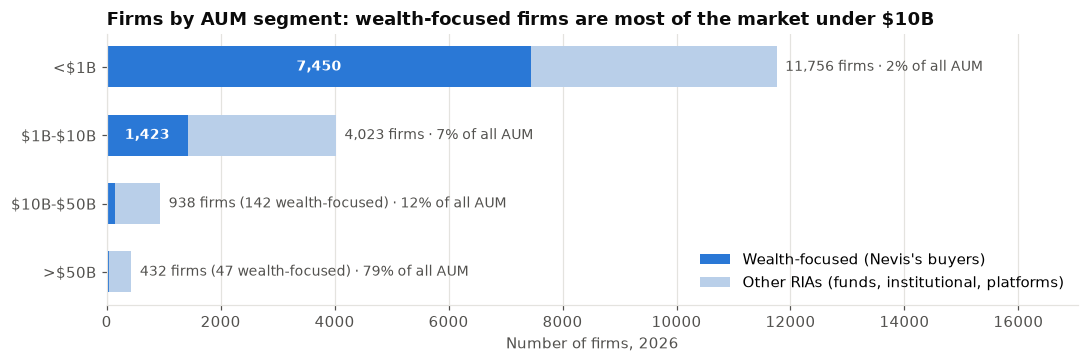

In [2]:
fig, ax = plt.subplots(figsize=(10, 3.4))
y = np.arange(len(SEGS))[::-1]
wf, other = seg["wealth_focused_firms"], seg["firms"] - seg["wealth_focused_firms"]
ax.barh(y, wf, color=BLUE, height=0.6, label="Wealth-focused (Nevis's buyers)")
ax.barh(y, other, left=wf, color=LIGHT, height=0.6, label="Other RIAs (funds, institutional, platforms)")
for yi, s in zip(y, SEGS):
    r = seg.loc[s]
    wf_note = "" if r["wealth_focused_firms"] > 600 else f" ({r['wealth_focused_firms']:,.0f} wealth-focused)"
    ax.text(r["firms"] + 150, yi, f"{r['firms']:,.0f} firms{wf_note} · {pct(r['share_of_aum'])} of all AUM",
            va="center", fontsize=9, color=MUTED)
    if r["wealth_focused_firms"] > 600:  # label inside the bar only where it fits
        ax.text(r["wealth_focused_firms"] / 2, yi, f"{r['wealth_focused_firms']:,.0f}", va="center",
                ha="center", fontsize=9, color="white", fontweight="bold")
ax.set_yticks(y, SEGS)
ax.set_xlim(0, seg["firms"].max() * 1.45)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Number of firms, 2026")
ax.legend(loc="lower right")
ax.set_title("Firms by AUM segment: wealth-focused firms are most of the market under $10B")
plt.tight_layout(); plt.show()

## 2. The core market: wealth-focused RIAs at <span>&#36;</span>1B–<span>&#36;</span>10B, up 52% since 2021
Firms move up a segment as they grow, so the number of wealth firms in each band is rising fast. The **<span>&#36;</span>1B–<span>&#36;</span>10B band went from 935 to 1,423 firms**. These firms have the budget and the operational pain, and they still make decisions independently.

*The 2023 dip reflects the 2022 market fall pulling firms back below <span>&#36;</span>1B. Some of the growth is market-driven, but the trend is clear.*

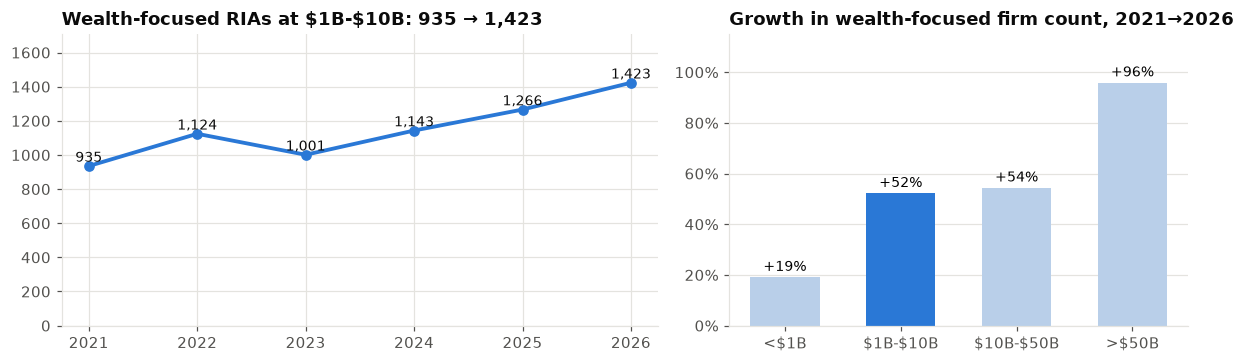

Segment,Wealth-focused firms 2021,Wealth-focused firms 2026,Change,All RIAs 2026
<$1B,"6,256","7,450",+19%,"11,756"
$1B-$10B,935,"1,423",+52%,"4,023"
$10B-$50B,92,142,+54%,938
>$50B,24,47,+96%,432


In [3]:
counts = (panel[panel["wealth_focused"]].groupby(["year", "segment"]).size().unstack()[SEGS])
change = counts.loc[2026] / counts.loc[2021] - 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1.3, 1]})
core = counts[CORE]
ax1.plot(core.index, core.values, color=BLUE, lw=2.5, marker="o")
for x, v in core.items():
    ax1.text(x, v + 25, f"{v:,.0f}", ha="center", fontsize=9, color=INK)
ax1.set_ylim(0, core.max() * 1.2)
ax1.set_xticks(core.index)
ax1.set_title(f"Wealth-focused RIAs at {CORE}: {core.iloc[0]:,.0f} → {core.iloc[-1]:,.0f}")

colors = [BLUE if s == CORE else LIGHT for s in SEGS]
bars = ax2.bar(SEGS, change.values, color=colors, width=0.6)
ax2.bar_label(bars, labels=[pct(v, True) for v in change], fontsize=9, padding=2)
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax2.set_ylim(0, change.max() * 1.2)
ax2.grid(axis="x", visible=False)
ax2.set_title("Growth in wealth-focused firm count, 2021→2026")
plt.tight_layout(); plt.show()

table(pd.DataFrame({
    "Segment": SEGS,
    "Wealth-focused firms 2021": counts.loc[2021].map("{:,.0f}".format).values,
    "Wealth-focused firms 2026": counts.loc[2026].map("{:,.0f}".format).values,
    "Change": [pct(v, True) for v in change],
    "All RIAs 2026": seg["firms"].map("{:,.0f}".format).values,
}))

## 3. Why they buy: the advisor capacity ceiling
**This is the core of the pitch.** From <span>&#36;</span>1B upward, the median wealth-firm advisor manages about **<span>&#36;</span>120–150M and 60–85 clients, whatever the firm's size**. Bigger wealth firms don't get more out of each advisor; they just hire more advisors.

Institutional managers keep climbing with size because they run funds, not client relationships. Digital platforms show what technology does to capacity.

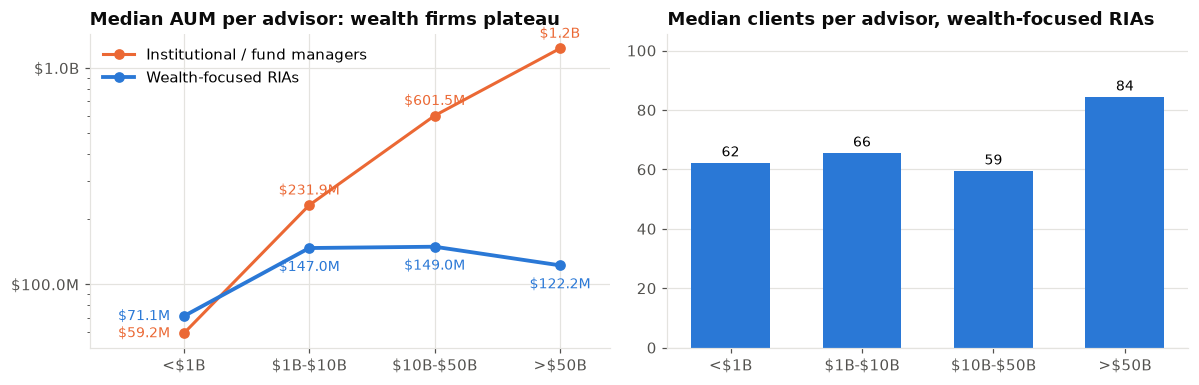

Benchmark: 115 digital platforms serve 25.6M clients with 3,056 advisors (~8,372 clients each) vs ~60–85 per advisor at a wealth firm.


In [4]:
WF = "wealth-focused (≥50% individual AUM)"
INST = "<50% individual AUM"
m = medians.pivot(index="segment", columns="firm_type", values=["aum_per_advisor", "clients_per_advisor"]).loc[SEGS]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(len(SEGS))
ax1.plot(x, m[("aum_per_advisor", INST)], color=ORANGE, lw=2, marker="o", label="Institutional / fund managers")
ax1.plot(x, m[("aum_per_advisor", WF)], color=BLUE, lw=2.5, marker="o", label="Wealth-focused RIAs")
for xi, (a, b) in enumerate(zip(m[("aum_per_advisor", WF)], m[("aum_per_advisor", INST)])):
    if xi == 0:  # lines cross here: label to the left of each point
        for v, col in [(a, BLUE), (b, ORANGE)]:
            ax1.annotate(money(v), (xi, v), textcoords="offset points", xytext=(-9, 0), ha="right", va="center",
                         fontsize=9, color=col)
        continue
    ax1.annotate(money(a), (xi, a), textcoords="offset points", xytext=(0, -15), ha="center", fontsize=9, color=BLUE)
    ax1.annotate(money(b), (xi, b), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=9, color=ORANGE)
ax1.set_yscale("log")
ax1.yaxis.set_major_formatter(lambda v, _: money(v))
ax1.set_xticks(x, SEGS)
ax1.set_xlim(-0.75, len(SEGS) - 0.6)
ax1.legend(loc="upper left")
ax1.set_title("Median AUM per advisor: wealth firms plateau")

cpa = m[("clients_per_advisor", WF)]
bars = ax2.bar(SEGS, cpa.values, color=BLUE, width=0.6)
ax2.bar_label(bars, labels=[f"{v:,.0f}" for v in cpa], fontsize=9, padding=2)
ax2.set_ylim(0, cpa.max() * 1.25)
ax2.grid(axis="x", visible=False)
ax2.set_title("Median clients per advisor, wealth-focused RIAs")
plt.tight_layout(); plt.show()

print(f"Benchmark: {len(platforms)} digital platforms serve {platforms['clients_raum'].sum() / 1e6:,.1f}M clients "
      f"with {platforms['advisors'].sum():,.0f} advisors (~{platforms['clients_raum'].sum() / platforms['advisors'].sum():,.0f} "
      f"clients each) vs ~60–85 per advisor at a wealth firm.")

**The most stretched advisors in the core segment.** These are wealth-focused firms with at least 20 clients, ranked by AUM per advisor. Each advisor carries many times the segment median.

In [5]:
c = capacity[(capacity["universe"] == "Wealth-focused RIAs") & (capacity["segment"] == CORE)].head(8)
table(pd.DataFrame({
    "Rank": c["rank"].values,
    "Firm": c["firm_name"].map(ap.display_name).values,
    "Location": (c["city"].str.title() + ", " + c["state"]).values,
    "AUM": c["aum"].map(money).values,
    "Advisors": c["advisors"].map("{:,.0f}".format).values,
    "AUM / advisor": c["aum_per_advisor"].map(money).values,
    "Clients / advisor": c["clients_per_advisor"].map("{:,.0f}".format).values,
}))

Rank,Firm,Location,AUM,Advisors,AUM / advisor,Clients / advisor
1,Provident Trust Company,"Waukesha, WI",$6.9B,2,$3.4B,518
2,Prowell Financial Management,"Exton, PA",$6.9B,3,$2.3B,25
3,Brave Warrior Advisors,"New York, NY",$5.6B,3,$1.9B,39
4,Tectonic Advisors,"Frisco, TX",$5.1B,3,$1.7B,792
5,Gleneagles Investment Advisors,"Atlanta, GA",$3.1B,2,$1.5B,26
6,Wharton Business Group,"Malvern, PA",$4.6B,3,$1.5B,41
7,Yale Capital,"St. Petersburg, FL",$5.6B,4,$1.4B,30
8,"Frank, Rimerman Advisors","Palo Alto, CA",$3.4B,3,$1.1B,36


## 4. The pain is growing: AUM is outrunning hiring
- The median wealth-focused firm grows AUM at **+15–24% a year** over three years, faster than RIAs overall.
- Headcount doesn't keep up. **1,347 wealth-focused firms** have had AUM outgrow advisor headcount by at least 10 points a year in **every** window (1, 3 and 5 years).

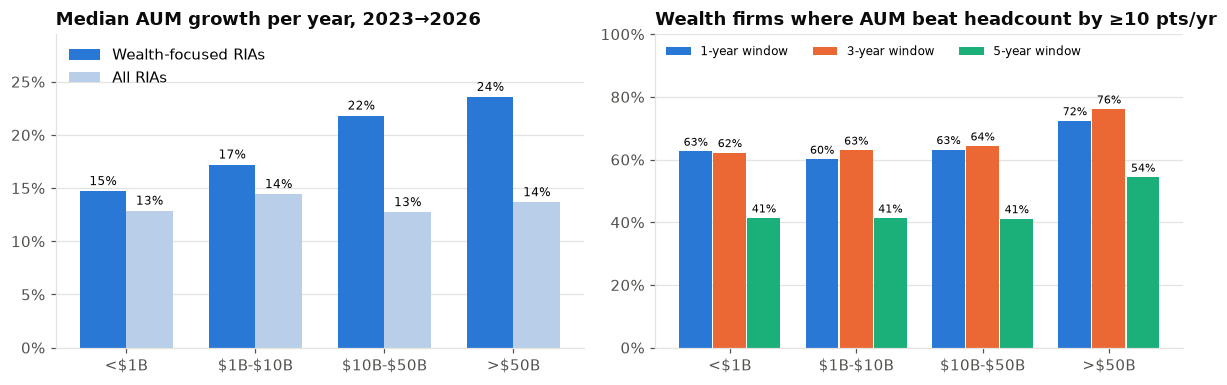

Persistently under-staffed wealth-focused firms (gap ≥10 pts/yr in all three windows): 1,347  ·  <$1B: 920  ·  $1B-$10B: 368  ·  $10B-$50B: 38  ·  >$50B: 21


In [6]:
g3 = growth[growth["horizon"] == "3y"].pivot(index="segment", columns="universe", values="median_cagr").loc[SEGS]
gp = gaps[gaps["universe"] == "Wealth-focused RIAs"].pivot(index="segment", columns="horizon",
                                                          values="material_gap_share").loc[SEGS]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
x, w = np.arange(len(SEGS)), 0.36
for i, (u, col) in enumerate([("Wealth-focused RIAs", BLUE), ("All RIAs", LIGHT)]):
    b = ax1.bar(x + (i - 0.5) * w, g3[u], width=w, color=col, label=u)
    ax1.bar_label(b, labels=[pct(v) for v in g3[u]], fontsize=8, padding=2)
ax1.set_xticks(x, SEGS)
ax1.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax1.set_ylim(0, g3.values.max() * 1.25)
ax1.grid(axis="x", visible=False)
ax1.legend(loc="upper left")
ax1.set_title("Median AUM growth per year, 2023→2026")

for i, (h, col) in enumerate([("1y", BLUE), ("3y", ORANGE), ("5y", AQUA)]):
    b = ax2.bar(x + (i - 1) * 0.27, gp[h], width=0.26, color=col, label=f"{h[0]}-year window")
    ax2.bar_label(b, labels=[pct(v) for v in gp[h]], fontsize=7, padding=2)
ax2.set_xticks(x, SEGS)
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax2.set_ylim(0, 1)
ax2.grid(axis="x", visible=False)
ax2.legend(loc="upper left", ncol=3, fontsize=8)
ax2.set_title("Wealth firms where AUM beat headcount by ≥10 pts/yr")
plt.tight_layout(); plt.show()

pw = persist[persist["wealth_focused"]].groupby("segment").size().reindex(SEGS, fill_value=0)
print(f"Persistently under-staffed wealth-focused firms (gap ≥10 pts/yr in all three windows): {pw.sum():,}  ·  "
      + "  ·  ".join(f"{s}: {n:,}" for s, n in pw.items()))

## 5. Who to call first: the scored lead list
Each wealth-focused firm scores **one point per buying signal**:

| Signal | What it means |
|---|---|
| **Growth** | Top-quartile AUM growth in its segment over 1, 3 *and* 5 years |
| **Capacity** | Top-quartile AUM per advisor in its segment: advisors are already stretched |
| **Staffing** | AUM has outgrown headcount by at least 10 pts/yr in every window |

Firms with two or more signals make the list. **Check first** marks firms whose growth may come from acquisitions, to verify before outreach.

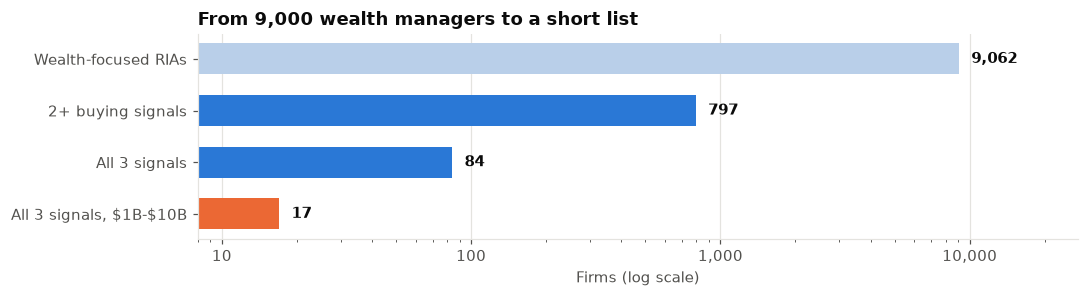

Segment,3 signals,2 signals,Total,Check first
<$1B,63,528,591,5
$1B-$10B,17,167,184,13
$10B-$50B,2,12,14,6
>$50B,2,6,8,0


In [7]:
n_wealth = int(latest["wealth_focused"].sum())
three = leads[leads["n_signals"] == 3]
stages = [("Wealth-focused RIAs", n_wealth), ("2+ buying signals", len(leads)), ("All 3 signals", len(three)),
          (f"All 3 signals, {CORE}", int((three["segment"] == CORE).sum()))]

fig, ax = plt.subplots(figsize=(10, 2.8))
labels, vals = zip(*stages)
y = np.arange(len(stages))[::-1]
bars = ax.barh(y, vals, color=[LIGHT, BLUE, BLUE, ORANGE], height=0.6)
for yi, v in zip(y, vals):
    ax.text(v * 1.12, yi, f"{v:,}", va="center", fontsize=10, fontweight="bold", color=INK)
ax.set_yticks(y, labels)
ax.set_xscale("log")
ax.set_xlim(8, n_wealth * 3)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Firms (log scale)")
ax.set_title("From 9,000 wealth managers to a short list")
plt.tight_layout(); plt.show()

mix = leads.pivot_table(index="segment", columns="n_signals", values="crd", aggfunc="count", fill_value=0).reindex(SEGS)
table(pd.DataFrame({"Segment": SEGS, "3 signals": mix[3].values, "2 signals": mix[2].values,
                    "Total": (mix[2] + mix[3]).values,
                    "Check first": leads.groupby("segment")["check_first"].sum().reindex(SEGS).values}))

**Start here: every three-signal firm in the core <span>&#36;</span>1B–<span>&#36;</span>10B segment**, ordered by AUM. The full list of 797 is in `outputs/priority_targets.csv`, with SEC number, website and location.

In [8]:
def lead_table(df):
    yes = lambda s: s.map({True: "✓", False: ""})
    table(pd.DataFrame({
        "Firm": df["firm"].values,
        "Location": (df["city"].str.title() + ", " + df["state"]).values,
        "Website": df["website"].fillna("–").values,
        "AUM": df["aum"].map(money).values,
        "Advisors": df["advisors"].map("{:,.0f}".format).values,
        "AUM / advisor": df["aum_per_advisor"].map(money).values,
        "AUM growth / yr (5y)": df["aum_cagr_5y"].map(lambda v: pct(v, True)).values,
        "Check first": yes(df["check_first"]).values,
    }))

lead_table(three[three["segment"] == CORE].sort_values("aum", ascending=False))

Firm,Location,Website,AUM,Advisors,AUM / advisor,AUM growth / yr (5y),Check first
Americana Partners,"Houston, TX",americanapartners.podbean.com,$9.1B,34,$267.7M,+39%,
Yale Capital,"St. Petersburg, FL",www.yalecapital.com,$5.6B,4,$1.4B,+22%,
Pennington Partners & Co.,"Bethesda, MD",pennington.addepar.com,$5.1B,10,$508.8M,+36%,✓
Aaron Wealth Advisors,"Chicago, IL",www.aaronwealth.com,$4.3B,9,$476.5M,+47%,
Vernal Point Advisors,"San Francisco, CA",www.vernalpoint.com,$3.9B,8,$492.2M,+33%,
Colter Lewis Investment Partners,"Greenwich, CT",www.colterlewis.com,$3.4B,12,$284.3M,+33%,
Point Olema Capital Partners,"San Francisco, CA",www.pointolema.com,$2.9B,4,$737.0M,+26%,
Traynor Capital Management,"Malvern, PA",www.traynorcapital.com,$2.4B,6,$403.4M,+27%,
Avestar Capital,"New York, NY",www.avestarcapital.com,$2.1B,6,$344.5M,+24%,✓
The Gleason Group,"Prospect, KY",www.gleason-group.net,$1.6B,5,$321.8M,+27%,


**Larger accounts with all three signals** (above <span>&#36;</span>10B): fewer firms, but bigger deals.

In [9]:
lead_table(three[three["segment"].isin(["$10B-$50B", ">$50B"])].sort_values("aum", ascending=False))

Firm,Location,Website,AUM,Advisors,AUM / advisor,AUM growth / yr (5y),Check first
Savant Wealth Management,"Rockford, IL",www.savantwealth.com,$55.6B,238,$233.6M,+40%,
MAI Capital Management,"Cleveland, OH",www.mai.capital,$52.1B,230,$226.5M,+41%,
Canterbury Consulting,"Newport Beach, CA",www.canterburyconsulting.com,$45.9B,25,$1.8B,+55%,✓
Clearstead; Clearstead Advisory Solutions,"Cleveland, OH",www.clearstead.com,$33.9B,104,$325.8M,+36%,


---
## 6. Recommendation and next steps
1. **Focus go-to-market on wealth-focused RIAs at <span>&#36;</span>1B–<span>&#36;</span>10B.** The segment has about 1,400 firms, is growing fast, and buys independently.
2. **Lead the pitch with the capacity ceiling:** "your advisors top out at about <span>&#36;</span>150M and 60–85 clients; we raise that."
3. **Work the list in order:** the **17 three-signal firms at <span>&#36;</span>1B–<span>&#36;</span>10B**, then the **167 two-signal firms** there, then the larger accounts above <span>&#36;</span>10B.
4. **Verify the 24 "check first" firms** before outreach, because their growth may come from acquisitions.
5. **Keep watching** the 115 digital platforms (competitive benchmark) and 52 investment managers used by RIAs (possible partners or channels).

**Decision needed:** who owns the lead list, and whether we pilot with a small set of firms first.

---
## Appendix: backup for questions

| Question | Answer |
|---|---|
| Isn't growth just the market going up? | Partly. AUM includes market returns. That's why the signals require **consistency** across 1, 3 and 5 years and a **10-point** materiality bar, not raw growth. |
| What counts as an "advisor"? | Form ADV has no advisor field. We use Item 5B(1), staff doing investment advisory work. Re-running with registered representatives (5B(3)) keeps the rankings (rank correlation 0.92–0.96). |
| Why exclude robo-advisers and fund managers? | They don't buy advisor-productivity tools, and "AUM per advisor" means nothing for a fund. Nothing is discarded: every ranking has an all-RIA version. |
| What's missing from the data? | State-registered advisers (mostly under <span>&#36;</span>100M) aren't in the SEC files. Acquisitions are only partly flagged. Firms that closed aren't measured. |
| Why not show the fastest 1-year growers? | Multi-fold one-year jumps (e.g. +600%) are usually acquisitions or re-registrations, not organic growth. The lead list uses 3- and 5-year consistency instead. |
| How reliable is this? | The pipeline has unit tests and the notebook has hard data checks. A fresh copy of the repo reproduces every output exactly. |

Full methodology and all 16 assumptions: `README.md` §4–§5. Full rankings for every question: `nevis-adv-analysis.ipynb`.

In [10]:
# Backup: market totals by segment (all RIAs), if asked
table(pd.DataFrame({
    "Segment": SEGS,
    "Firms": seg["firms"].map("{:,.0f}".format).values,
    "Share of firms": seg["share_of_firms"].map(pct).values,
    "Total AUM": seg["total_aum"].map(money).values,
    "Share of AUM": seg["share_of_aum"].map(pct).values,
    "Median advisors": seg["median_advisors"].map("{:,.0f}".format).values,
    "Wealth-focused firms": seg["wealth_focused_firms"].map("{:,.0f}".format).values,
}))

Segment,Firms,Share of firms,Total AUM,Share of AUM,Median advisors,Wealth-focused firms
<$1B,"11,756",69%,$3.7T,2%,3,"7,450"
$1B-$10B,"4,023",23%,$12.4T,7%,12,"1,423"
$10B-$50B,938,5%,$20.8T,12%,37,142
>$50B,432,3%,$140.2T,79%,126,47
